# 3 · Kwantowa telepatia

**Koło Naukowe Qubit, PWr** · gry nielokalne na 3 i 4 kubitach (Qiskit + IQM)

Trzy osoby siedzą w osobnych pokojach i nie mogą się porozumieć. Dostają pytania, odpowiadają jednym bitem.
Żadna klasyczna strategia nie wygra częściej niż w **75%** rund. Gracze, którzy dzielą **3 splątane kubity**,
wygrywają w **100%**. Z zewnątrz wygląda to jak telepatia.

Plan:
1. Gra GHZ: sprawdzisz własną strategię, a potem komputer sprawdzi **wszystkie** strategie klasyczne.
2. Strategia kwantowa na 3 kubitach: idealnie i na modelu Odry 5 z szumem.
3. Ile szumu wytrzyma „telepatia”?
4. Poziom 2: magiczny kwadrat na 4 kubitach. Tu szum wygrywa z kwantem. Da się to odwrócić?

> 📚 To ta sama fizyka, za którą Aspect, Clauser i Zeilinger dostali Nobla w 2022 r. (testy nierówności Bella).
> Doczytaj: [Brassard, Broadbent, Tapp, Quantum Pseudo-Telepathy](https://arxiv.org/abs/quant-ph/0407221).

In [2]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, SparsePauliOp
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
from iqm.qiskit_iqm import IQMFakeAdonis

sim = AerSimulator(seed_simulator=42)   # idealny symulator
adonis = IQMFakeAdonis()                # model 5-kubitowego komputera IQM z szumem (topologia jak Odra 5)
SHOTS = 2000

## 1. Zasady gry GHZ

Gracze: **Ala**, **Bartek**, **Celina**. Przed grą mogą ustalić strategię. Potem siedzą w osobnych pokojach.

1. Sędzia losuje trzy bity pytań $x, y, z$, zawsze z **parzystą liczbą jedynek**: `000`, `011`, `101` albo `110`.
2. Ala dostaje tylko $x$, Bartek tylko $y$, Celina tylko $z$.
3. Każdy odpowiada jednym bitem: $a, b, c$.
4. Wygrywają, gdy $a \oplus b \oplus c = x \lor y \lor z$.

Po ludzku:

| pytania | co musi wyjść |
|---|---|
| `000` | parzysta liczba jedynek w odpowiedziach |
| `011`, `101`, `110` | nieparzysta liczba jedynek w odpowiedziach |

In [3]:
QUESTIONS = ["000", "011", "101", "110"]

def ghz_win(xyz, abc):
    x, y, z = (int(q) for q in xyz)
    a, b, c = (int(q) for q in abc)
    return (a ^ b ^ c) == (x | y | z)

def score(strategy):
    # strategy[i] = (odpowiedź gracza i na pytanie 0, odpowiedź na pytanie 1)
    wins = 0
    for xyz in QUESTIONS:
        abc = "".join(str(strategy[i][int(xyz[i])]) for i in range(3))
        ok = ghz_win(xyz, abc)
        wins += ok
        print(f"pytania {xyz} -> odpowiedzi {abc}  {'wygrana' if ok else 'PRZEGRANA'}")
    print(f"Wynik: {wins}/4 = {wins / 4:.0%}")
    return wins / 4

### Twoja kolej

Wymyśl strategię. Dla każdego gracza wpisz parę: (co odpowiada na pytanie `0`, co odpowiada na pytanie `1`).
Spróbuj dostać 4/4.

In [4]:
my_strategy = [
    (0, 1),   # Ala
    (0, 1),   # Bartek
    (0, 1),   # Celina
]
score(my_strategy);

pytania 000 -> odpowiedzi 000  wygrana
pytania 011 -> odpowiedzi 011  PRZEGRANA
pytania 101 -> odpowiedzi 101  PRZEGRANA
pytania 110 -> odpowiedzi 110  PRZEGRANA
Wynik: 1/4 = 25%


### Dowód brute force: 75% to sufit

Każdy gracz ma tylko 4 możliwe strategie (odpowiedź na `0` i na `1`), więc wszystkich strategii drużyny jest
$4^3 = 64$. Sprawdzamy każdą.

Losowanie (rzut monetą, wspólna kartka z losowymi bitami) nie pomaga: strategia losowa to mieszanka
deterministycznych, więc jej średni wynik nie przekroczy najlepszej z nich.

Dlaczego nie da się 4/4? Gdyby się dało, cztery warunki wygranej (dla `000`, `011`, `101`, `110`) zachodziłyby naraz.
Po zsumowaniu ich stronami (XOR) każda odpowiedź pojawia się dwa razy i się kasuje: wychodzi $0 = 1$. Sprzeczność.

Sprawdzone strategie: 64
Najlepszy wynik klasyczny: 3 / 4 = 75%


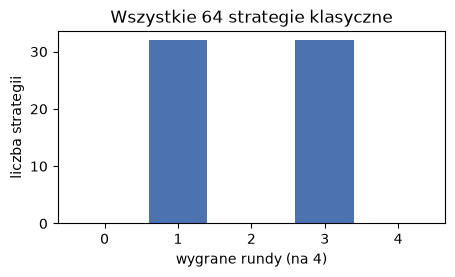

In [5]:
answers = list(itertools.product([0, 1], repeat=2))   # (odp. na 0, odp. na 1) dla jednego gracza
results = []
for strategy in itertools.product(answers, repeat=3):
    wins = sum(ghz_win(xyz, "".join(str(strategy[i][int(xyz[i])]) for i in range(3))) for xyz in QUESTIONS)
    results.append(wins)

print("Sprawdzone strategie:", len(results))
print("Najlepszy wynik klasyczny:", max(results), "/ 4 =", f"{max(results) / 4:.0%}")
plt.figure(figsize=(5, 2.5))
plt.hist(results, bins=np.arange(-0.5, 5.5), rwidth=0.8, color="#4C72B0")
plt.xlabel("wygrane rundy (na 4)"); plt.ylabel("liczba strategii"); plt.title("Wszystkie 64 strategie klasyczne")
plt.show()

## 2. Strategia kwantowa

Przed grą gracze przygotowują **stan GHZ** i każdy zabiera do pokoju jeden kubit:

$$|\mathrm{GHZ}\rangle = \frac{|000\rangle + |111\rangle}{\sqrt 2}$$

W grze każdy robi jedno:
- pytanie `0` → mierzy swój kubit w bazie **X** (bramka `H`, potem pomiar),
- pytanie `1` → mierzy w bazie **Y** (bramki `S†`, `H`, potem pomiar),

i odpowiada wynikiem pomiaru. Nikt nic nie wysyła. Każdy pomiar osobno daje losowe 0 albo 1.

<IPython.core.display.Latex object>

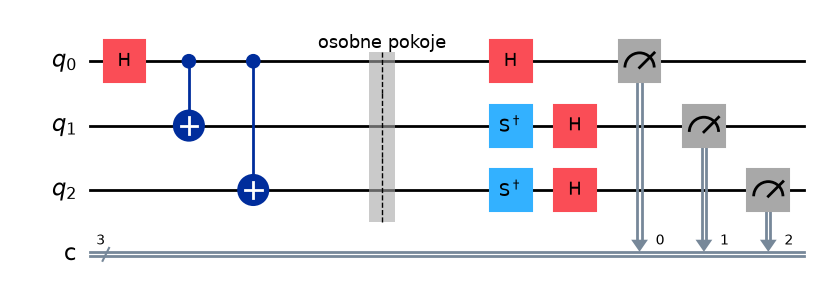

In [6]:
def ghz_state():
    qc = QuantumCircuit(3)
    qc.h(0)
    qc.cx(0, 1)
    qc.cx(0, 2)
    return qc

def ghz_game_circuit(xyz):
    qc = QuantumCircuit(3, 3)
    qc.compose(ghz_state(), inplace=True)
    qc.barrier(label="osobne pokoje")
    for player, q in enumerate(xyz):
        if q == "1":
            qc.sdg(player)
        qc.h(player)
    qc.measure([0, 1, 2], [0, 1, 2])
    return qc

display(Statevector(ghz_state()).draw("latex"))
ghz_game_circuit("011").draw("mpl")

### Dlaczego to działa

Parzystość odpowiedzi $a \oplus b \oplus c$ to pomiar iloczynu obserwabli trzech graczy, np. $X \otimes Y \otimes Y$.
Wartość $+1$ znaczy parzystą liczbę jedynek, $-1$ nieparzystą. Dla stanu GHZ te iloczyny mają **pewne** wartości:

In [7]:
psi = Statevector(ghz_state())
for xyz in QUESTIONS:
    pauli = "".join("Y" if q == "1" else "X" for q in reversed(xyz))   # Qiskit czyta kubity od prawej
    value = psi.expectation_value(SparsePauliOp(pauli)).real
    print(f"pytania {xyz}: <{pauli[::-1]}> = {value:+.0f}  -> {'parzysta' if value > 0 else 'nieparzysta'} liczba jedynek")

pytania 000: <XXX> = +1  -> parzysta liczba jedynek
pytania 011: <XYY> = -1  -> nieparzysta liczba jedynek
pytania 101: <YXY> = -1  -> nieparzysta liczba jedynek
pytania 110: <YYX> = -1  -> nieparzysta liczba jedynek


Dokładnie to, czego wymaga gra. Klasycznie się nie da, bo klasyczny gracz musiałby mieć **z góry ustalone**
odpowiedzi na oba pytania, a tamten dowód pokazał, że takie odpowiedzi nie istnieją.
Kubity nie mają ustalonych odpowiedzi przed pomiarem. To jest sedno.

Teraz zagrajmy: 4 rodzaje pytań × 2000 rund.

In [8]:
def ghz_win_rate(backend, shots=SHOTS):
    wins = 0
    for xyz in QUESTIONS:
        qc = transpile(ghz_game_circuit(xyz), backend, seed_transpiler=1)
        counts = backend.run(qc, shots=shots, seed_simulator=7).result().get_counts()
        wins += sum(n for bits, n in counts.items() if ghz_win(xyz, bits[::-1]))
    return wins / (len(QUESTIONS) * shots)

ghz_ideal = ghz_win_rate(sim)
ghz_odra = ghz_win_rate(adonis)
print(f"klasycznie (najlepiej):  75.0%")
print(f"kwantowo, idealnie:      {ghz_ideal:.1%}")
print(f"kwantowo, model Odry 5:  {ghz_odra:.1%}")

klasycznie (najlepiej):  75.0%
kwantowo, idealnie:      100.0%
kwantowo, model Odry 5:  86.3%


Nawet z szumem kubity wygrywają częściej, niż pozwala jakakolwiek klasyczna strategia.

> ⚠️ Uczciwie: to nie jest prawdziwy test Bella. Wszystkie trzy kubity siedzą na jednym chipie, więc w zasadzie
> „gracze” mogliby się komunikować przez sprzęt. Prawdziwe testy (Nobel 2022) rozsuwają cząstki tak daleko,
> że sygnał nie zdąży dolecieć nawet z prędkością światła.

## 3. Ile szumu wytrzyma telepatia?

Dokładamy coraz większy szum (depolaryzację) do bramek `CX` i patrzymy, kiedy kwant spada poniżej 75%.

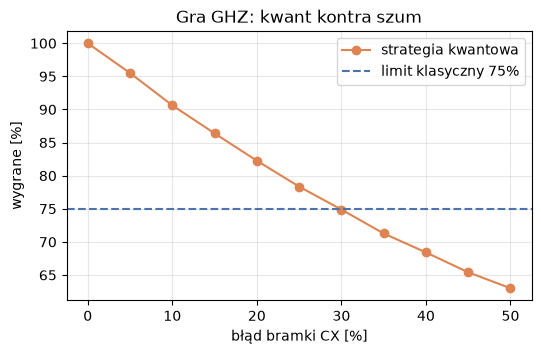

In [9]:
noise_levels = np.linspace(0, 0.5, 11)
rates = []
for p in noise_levels:
    noise = NoiseModel()
    noise.add_all_qubit_quantum_error(depolarizing_error(p, 2), ["cx"])
    rates.append(ghz_win_rate(AerSimulator(noise_model=noise, seed_simulator=1)))

plt.figure(figsize=(6, 3.5))
plt.plot(noise_levels * 100, np.array(rates) * 100, "o-", color="#DD8452", label="strategia kwantowa")
plt.axhline(75, color="#4C72B0", ls="--", label="limit klasyczny 75%")
plt.xlabel("błąd bramki CX [%]"); plt.ylabel("wygrane [%]")
plt.title("Gra GHZ: kwant kontra szum"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

Kwant prowadzi aż do ok. 30% błędu na bramce `CX`. Dzisiejsze komputery mają błąd rzędu 1-5%,
więc 3-kubitowa telepatia działa z dużym zapasem.

## 4. Poziom 2: magiczny kwadrat (4 kubity)

Teraz dwoje graczy: **Ala** i **Bartek**. Tabela 3×3 z bitami.

1. Ala dostaje numer **wiersza** $r$ i wypełnia go trzema bitami z **parzystą** liczbą jedynek.
2. Bartek dostaje numer **kolumny** $c$ i wypełnia ją trzema bitami z **nieparzystą** liczbą jedynek.
3. Wygrywają, gdy w polu na przecięciu $(r, c)$ wpiszą ten sam bit.

Klasycznie: gdyby istniała cała tabela spełniająca wszystkie warunki, suma jej bitów byłaby
parzysta (liczona wierszami) i nieparzysta (liczona kolumnami) naraz. Sprzeczność. Najlepiej da się **8/9 ≈ 88.9%**.

In [10]:
even = [t for t in itertools.product([0, 1], repeat=3) if sum(t) % 2 == 0]
odd = [t for t in itertools.product([0, 1], repeat=3) if sum(t) % 2 == 1]

best = 0
for alice in itertools.product(even, repeat=3):      # odpowiedź Ali dla każdego wiersza
    for bob in itertools.product(odd, repeat=3):     # odpowiedź Bartka dla każdej kolumny
        wins = sum(alice[r][c] == bob[c][r] for r in range(3) for c in range(3))
        best = max(best, wins)
print(f"Sprawdzone strategie: {len(even) ** 3 * len(odd) ** 3}")
print(f"Najlepszy wynik klasyczny: {best}/9 = {best / 9:.1%}")

Sprawdzone strategie: 4096
Najlepszy wynik klasyczny: 8/9 = 88.9%


### Strategia kwantowa

Ala i Bartek dzielą **dwie pary Bella** (4 kubity): Ala ma kubity 0 i 1, Bartek kubity 2 i 3.
Każde pole tabeli to obserwabla na dwóch kubitach (wartość $+1$ → bit 0, $-1$ → bit 1):

|  | kolumna 0 | kolumna 1 | kolumna 2 |
|---|---|---|---|
| **wiersz 0** | $X \otimes I$ | $I \otimes X$ | $X \otimes X$ |
| **wiersz 1** | $I \otimes Z$ | $Z \otimes I$ | $Z \otimes Z$ |
| **wiersz 2** | $-X \otimes Z$ | $-Z \otimes X$ | $Y \otimes Y$ |

W każdym wierszu iloczyn obserwabli to $+I$ (parzystość), w każdej kolumnie $-I$ (nieparzystość).
Obserwable w jednym wierszu (i w jednej kolumnie) są przemienne, więc da się je zmierzyć naraz.
Na parach Bella Ala i Bartek, mierząc to samo pole, zawsze dostają tę samą wartość.

Pomiar dwóch obserwabli z wiersza wystarczy, trzecią wyliczamy z parzystości. Obwody pomiarowe:

| kto | co mierzy | bramki przed pomiarem w bazie Z |
|---|---|---|
| Ala, wiersz 0 | $XI$, $IX$ | `H`, `H` |
| Ala, wiersz 1 | $IZ$, $ZI$ | nic |
| Ala, wiersz 2 | $XZ$, $ZX$ | `CZ`, potem `H`, `H` |
| Bartek, kolumna 0 | $XI$, $IZ$ | `H` na pierwszym |
| Bartek, kolumna 1 | $IX$, $ZI$ | `H` na drugim |
| Bartek, kolumna 2 | $XX$, $ZZ$ | `CX`, potem `H` na pierwszym (pomiar w bazie Bella) |

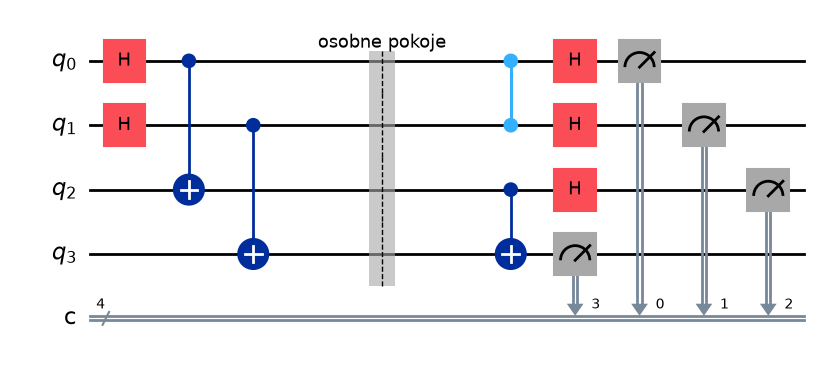

In [11]:
def measure_row(qc, r, q0, q1):
    if r == 0:
        qc.h(q0); qc.h(q1)
    elif r == 2:
        qc.cz(q0, q1); qc.h(q0); qc.h(q1)

def measure_col(qc, c, q0, q1):
    if c == 0:
        qc.h(q0)
    elif c == 1:
        qc.h(q1)
    else:
        qc.cx(q0, q1); qc.h(q0)

def alice_answer(r, m0, m1):
    if r == 0: a = (m0, m1)          # XI, IX
    if r == 1: a = (m1, m0)          # IZ, ZI
    if r == 2: a = (m0 ^ 1, m1 ^ 1)  # -XZ, -ZX (minus odwraca bit)
    return (*a, a[0] ^ a[1])         # trzecie pole: parzystość wiersza

def bob_answer(c, m0, m1):
    if c == 0: b = (m0, m1)          # XI, IZ
    if c == 1: b = (m1, m0)          # IX, ZI
    if c == 2: b = (m0, m1)          # XX, ZZ
    return (*b, b[0] ^ b[1] ^ 1)     # trzecie pole: nieparzystość kolumny

def square_circuit(r, c):
    qc = QuantumCircuit(4, 4)
    qc.h(0); qc.cx(0, 2)             # para Bella: kubit 0 (Ala) + kubit 2 (Bartek)
    qc.h(1); qc.cx(1, 3)             # para Bella: kubit 1 (Ala) + kubit 3 (Bartek)
    qc.barrier(label="osobne pokoje")
    measure_row(qc, r, 0, 1)
    measure_col(qc, c, 2, 3)
    qc.measure(range(4), range(4))
    return qc

square_circuit(2, 2).draw("mpl")

In [12]:
def square_win_rate(backend, shots=SHOTS):
    wins = 0
    for r, c in itertools.product(range(3), repeat=2):
        qc = transpile(square_circuit(r, c), backend, seed_transpiler=1)
        counts = backend.run(qc, shots=shots, seed_simulator=7).result().get_counts()
        for bits, n in counts.items():
            m = [int(b) for b in bits[::-1]]
            a, b = alice_answer(r, m[0], m[1]), bob_answer(c, m[2], m[3])
            wins += n * (a[c] == b[r])
    return wins / (9 * shots)

square_ideal = square_win_rate(sim)
square_odra = square_win_rate(adonis)
print(f"klasycznie (najlepiej):  {8 / 9:.1%}")
print(f"kwantowo, idealnie:      {square_ideal:.1%}")
print(f"kwantowo, model Odry 5:  {square_odra:.1%}")

klasycznie (najlepiej):  88.9%
kwantowo, idealnie:      100.0%
kwantowo, model Odry 5:  85.9%


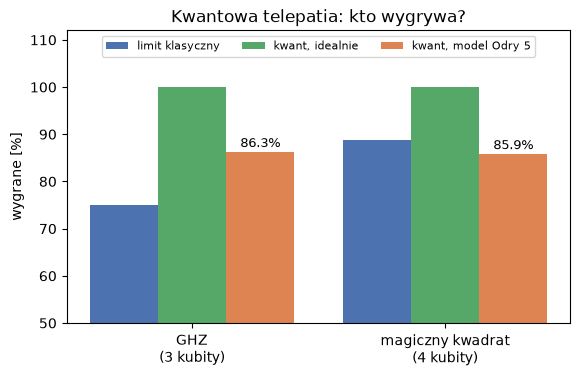

In [13]:
labels = ["GHZ\n(3 kubity)", "magiczny kwadrat\n(4 kubity)"]
classical = [0.75, 8 / 9]
ideal = [ghz_ideal, square_ideal]
odra = [ghz_odra, square_odra]

x = np.arange(2)
plt.figure(figsize=(6.5, 3.8))
plt.bar(x - 0.27, np.array(classical) * 100, 0.27, label="limit klasyczny", color="#4C72B0")
plt.bar(x, np.array(ideal) * 100, 0.27, label="kwant, idealnie", color="#55A868")
plt.bar(x + 0.27, np.array(odra) * 100, 0.27, label="kwant, model Odry 5", color="#DD8452")
for xi, v in zip(x + 0.27, odra):
    plt.text(xi, v * 100 + 1, f"{v:.1%}", ha="center", fontsize=9)
plt.xticks(x, labels); plt.ylim(50, 112); plt.ylabel("wygrane [%]")
plt.title("Kwantowa telepatia: kto wygrywa?"); plt.legend(loc="upper center", ncol=3, fontsize=8); plt.show()

**Wynik:** na 3 kubitach kwant wygrywa z klasyką nawet z szumem. Na 4 kubitach przewaga klasyki to tylko
1/9, a szum (więcej bramek dwukubitowych, kubity muszą się wymieniać przez centrum gwiazdy) spycha
wynik **poniżej** 88.9%. Na tym modelu Odry 5 magiczny kwadrat przegrywa z klasyką.

Topologia gwiazdy ma znaczenie: każda para Bella potrzebuje połączenia, a pomiar Ali w wierszu 2 i Bartka
w kolumnie 2 to kolejne bramki dwukubitowe. Zobacz, ile ich wyszło po kompilacji:

In [14]:
for r, c in [(0, 0), (2, 2)]:
    tqc = transpile(square_circuit(r, c), adonis, seed_transpiler=1)
    print(f"wiersz {r}, kolumna {c}: bramek CZ = {tqc.count_ops().get('cz', 0)}, głębokość = {tqc.depth()}")

wiersz 0, kolumna 0: bramek CZ = 5, głębokość = 12
wiersz 2, kolumna 2: bramek CZ = 10, głębokość = 21


## 5. Wyzwanie projektowe

**Czy da się wygrać magiczny kwadrat powyżej 88.9% na modelu Odry 5, a potem na prawdziwej Odrze 5?**
Nie wiemy, czy się da. Pomysły:

1. **Lepsze rozmieszczenie kubitów**: `transpile(..., initial_layout=[...])`. Który kubit powinien siedzieć w centrum gwiazdy?
2. **Prostsze obwody pomiarowe**: czy da się zmierzyć wiersz 2 i kolumnę 2 mniejszą liczbą bramek `CZ`?
3. **Korekcja błędów odczytu** (readout mitigation): zmierz, jak często kubit 0 czyta się jako 1 i odwrotnie, i popraw statystykę.
4. **Prawdziwy sprzęt**: uruchom gry GHZ i kwadrat na Odrze 5 albo maszynach IQM w Finlandii i porównaj z modelem.
5. **Gra dla 5 graczy**: stan GHZ na wszystkich 5 kubitach Odry 5 (gra Mermina dla $n$ graczy). Jak szybko rośnie
   przewaga kwantu, a jak szybko szum?

Każdy z tych punktów to osobny mini-projekt na 1-2 spotkania.